# Next-token, multi-token, joint multi-token and next-latent prediction, built step by step

**TL;DR.** Almost every language model is trained to predict one token ahead, and in principle that is enough, because by the chain rule it models any sequence distribution. In practice a model trained this way can learn shortcuts that fit the training targets without building the internal state needed to plan, and three recent proposals change *what the hidden state is asked to predict* to push against that. Gloeckle et al., 2024, [Better & Faster Large Language Models via Multi-token Prediction](https://arxiv.org/abs/2404.19737) add independent output heads for the next $n$ tokens and *report* that 13B-parameter models solve 12% more HumanEval and 17% more MBPP problems than a next-token baseline, and that 4-token prediction can speed up inference up to 3x with self-speculative decoding. Ahn et al., 2025, [Efficient Joint Prediction of Multiple Future Tokens](https://arxiv.org/abs/2503.21801) (joint multi-token prediction, JTP) feed teacher-forced future tokens through a small bottleneck so the hidden state has to carry the plan. Teoh et al., 2025, [Next-Latent Prediction Transformers Learn Compact World Models](https://arxiv.org/abs/2511.05963) (NextLat) instead train the model to predict its *own next hidden state* from the current one and the next token. In this notebook we write all four objectives from scratch in PyTorch, starting from a numeric example for each, check them against library calls and against properties the papers claim, and then train all four on the small star-graph planning task that Ahn et al. use. **Headline result from our runs:** on the star graph $G(2,5)$ (chance 50%), after 12,000 training steps the exact-path solve rate was 80.9% for NextLat, 55.3% for JTP, 46.3% for the next-token baseline and 39.1% for independent multi-token heads (one seed each; the next-token baseline sits at chance, as the shortcut analysis in section 2 predicts). The figures and speed-ups quoted above (12%, 17%, 3x, 3.3x) are *reported* by the papers and not measured here.

**Scope.** Our experiments are tiny (a 3-layer, 128-dimensional transformer, one synthetic task, a single seed, CPU). They say whether each mechanism *can* work on a task built to need it; they say nothing about language modelling at scale. The figures taken from the papers are credited in their captions.

**Contents**
1. Next-token prediction
2. A task where it struggles: the star graph
3. Multi-token prediction
4. Joint multi-token prediction
5. Next-latent prediction
6. Comparing the four on the star graph
7. What did not work and what each costs
8. Closing thoughts

In [1]:
import math, os, sys, itertools, time, json
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import Markdown, Image as IPImage, display
sys.path.insert(0, os.getcwd())
import predkit as pk, predkit_viz as viz
DEVICE = pk.DEVICE
torch.manual_seed(0)
os.makedirs("assets", exist_ok=True)
print("device:", DEVICE, "| torch", torch.__version__)

_CHECKS = []
def check(name, cond, detail=""):
    _CHECKS.append((name, bool(cond), detail)); assert cond, f"CHECK FAILED: {name} {detail}"
def report():
    for n, c, d in _CHECKS: print(("PASS " if c else "FAIL ") + n + (f"   [{d}]" if d else ""))
    print(f"\n{sum(c for _, c, _ in _CHECKS)}/{len(_CHECKS)} checks passed")
def show_paper_fig(fn, caption, width=9):
    img = plt.imread(f"assets/{fn}"); h = img.shape[0] / img.shape[1] * width
    fig, ax = plt.subplots(figsize=(width, h)); ax.imshow(img); ax.axis("off"); plt.tight_layout(); plt.show()
    display(Markdown(f"<sub>**Figure.** {caption}</sub>"))

device: cpu | torch 2.14.1


Before the first section, here is the picture that the rest of the notebook unpacks. The four panels are Figure 1 of Teoh et al., 2025; read left to right, each one answers "what is the hidden state $h_3$, computed from tokens $X_1,X_2,X_3$, asked to explain?"

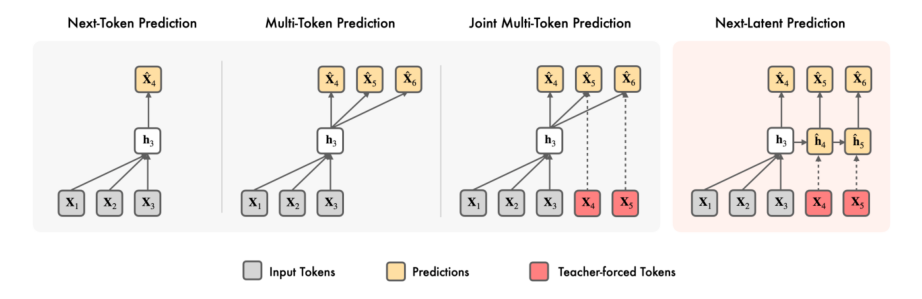

<sub>**Figure.** Reproduced from Figure 1 of Teoh et al., 2025 ([arXiv:2511.05963](https://arxiv.org/abs/2511.05963)). Grey = input tokens, yellow = predictions, red = teacher-forced tokens (tokens from the data that are fed in even though the model has not predicted them yet). Notice that the first three panels differ only in the arrows leaving h3 and in whether red tokens are used; the fourth panel adds new latent states (h-hat 4, h-hat 5) that never exist in a standard transformer.</sub>

In [2]:
show_paper_fig("fig_nextlat_overview.png", "Reproduced from Figure 1 of Teoh et al., 2025 ([arXiv:2511.05963](https://arxiv.org/abs/2511.05963)). Grey = input tokens, yellow = predictions, red = teacher-forced tokens (tokens from the data that are fed in even though the model has not predicted them yet). Notice that the first three panels differ only in the arrows leaving h3 and in whether red tokens are used; the fourth panel adds new latent states (h-hat 4, h-hat 5) that never exist in a standard transformer.", 10)

## 1. Next-token prediction

**A tiny example.** Take the five-token sequence "the cat sat on the" with a six-word vocabulary. The model reads the first four tokens and, at every position, assigns a probability to every word. Training looks at the probability it gave to the word that actually came next. Suppose the probabilities assigned to the *correct* next word are 0.50, 0.25, 0.80 and 0.10 at the four positions. The loss is the average of $-\log$ of those numbers.

In [3]:
vocab = ["the", "cat", "sat", "on", "mat", "dog"]; ids = torch.tensor([0, 1, 2, 3, 0])            # "the cat sat on the"
x, y = ids[:-1], ids[1:]                                                                        # inputs and shifted targets
print("inputs :", [vocab[i] for i in x]); print("targets:", [vocab[i] for i in y])
p_correct = torch.tensor([0.50, 0.25, 0.80, 0.10])
by_hand = -torch.log(p_correct); print("per-position loss (by hand):", by_hand.tolist(), "-> mean", by_hand.mean().item())
# the same thing through logits: build logits whose softmax gives exactly these probabilities for the correct word
logits = torch.full((4, 6), -10.0); rest = (1 - p_correct) / 5
for t in range(4):
    logits[t] = torch.log(rest[t]); logits[t, y[t]] = torch.log(p_correct[t])
print("cross_entropy:", F.cross_entropy(logits, y).item())
check("hand-computed next-token loss equals F.cross_entropy", abs(by_hand.mean().item() - F.cross_entropy(logits, y).item()) < 1e-6)

inputs : ['the', 'cat', 'sat', 'on']
targets: ['cat', 'sat', 'on', 'the']
per-position loss (by hand): [0.6931471824645996, 1.3862943649291992, 0.2231435328722, 2.3025851249694824] -> mean 1.1512925624847412
cross_entropy: 1.1512925624847412


**General definition.** For a sequence $x_1,\dots,x_T$ and a model with hidden state $h_t$ at position $t$ and an output head that turns $h_t$ into a distribution over the vocabulary,

$$\mathcal L_{\text{NTP}}=-\frac1{T-1}\sum_{t=1}^{T-1}\log p_\theta(x_{t+1}\mid h_t),\qquad h_t=f_\theta(x_1,\dots,x_t).$$

One position contributes one **one-hot target**: the loss only sees how much probability landed on a single word. The causal mask in the transformer guarantees that $h_t$ depends only on $x_{\le t}$, so every position of the sequence can be trained in parallel from one forward pass.

**How it is implemented.** Two operations: shift the sequence by one to make targets, and apply a causal attention mask. We write both explicitly below, then run a one-layer attention on a toy input to confirm that changing a *future* token leaves earlier hidden states untouched.

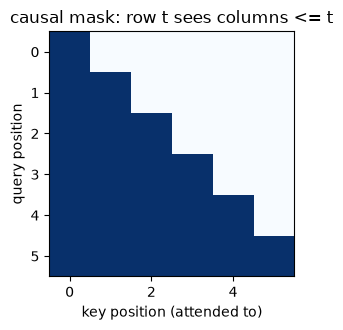

<sub>**Figure.** The lower triangle is visible context. Notice that this single mask is what lets one forward pass produce a valid training signal at every position at once.</sub>

scratch NTP loss 1.7798442840576172 | library 1.7798442840576172


In [4]:
T = 6
causal = torch.triu(torch.ones(T, T, dtype=torch.bool), 1)                    # True = may NOT attend
fig, ax = plt.subplots(figsize=(3.6, 3.4)); ax.imshow(~causal.cpu(), cmap="Blues"); ax.set_xlabel("key position (attended to)"); ax.set_ylabel("query position"); ax.set_title("causal mask: row t sees columns <= t")
plt.tight_layout(); plt.show()
display(Markdown("<sub>**Figure.** The lower triangle is visible context. Notice that this single mask is what lets one forward pass produce a valid training signal at every position at once.</sub>"))

def next_token_loss(h, head, seq, mask=None):
    """h: (B,T-1,dim) hidden states for inputs seq[:, :-1]; head: Linear(dim, V). Target for position t is seq[:, t+1]."""
    logits = head(h); y = seq[:, 1:]
    logp = F.log_softmax(logits, -1).gather(-1, y[..., None])[..., 0]            # log p(correct word) at every position
    m = torch.ones_like(logp) if mask is None else mask
    return -(logp * m).sum() / m.sum()

torch.manual_seed(1); emb = nn.Embedding(6, 16); head = nn.Linear(16, 6, bias=False); seq = ids[None]
attn = nn.MultiheadAttention(16, 2, batch_first=True)
def hidden(tokens): e = emb(tokens); return attn(e, e, e, attn_mask=torch.triu(torch.ones(tokens.shape[1], tokens.shape[1], dtype=torch.bool), 1), need_weights=False)[0]
h = hidden(seq[:, :-1]); loss_mine = next_token_loss(h, head, seq); loss_lib = F.cross_entropy(head(h).reshape(-1, 6), seq[:, 1:].reshape(-1))
print("scratch NTP loss", loss_mine.item(), "| library", loss_lib.item())
check("scratch next-token loss equals F.cross_entropy on a real forward pass", abs(loss_mine.item() - loss_lib.item()) < 1e-6)
alt = seq.clone(); alt[0, 4] = 5                                               # change a FUTURE token (the last one)
check("changing a later token leaves earlier hidden states unchanged (causality)", torch.allclose(hidden(seq[:, :-1])[:, :3], hidden(alt[:, :-1])[:, :3], atol=1e-6))

The objective is cheap and it scales, and it has an honest cost: each position supplies one token's worth of supervision. If a model can reach the right answer by looking back at the context token by token instead of summarising it, nothing in the loss pushes it to build a summary. The next section shows a task where that matters.

## 2. A task where it struggles: the star graph

**A tiny example.** Bachmann and Nagarajan, 2024 ([The Pitfalls of Next-Token Prediction](https://arxiv.org/abs/2403.06963)) introduced the star graph task, which Ahn et al. use. A graph has one centre node and $d$ paths of $l$ nodes leaving it. The prompt lists all edges in shuffled order, then a start node (always the centre) and a goal node (the end of one branch); the answer is the path from start to goal. With $d=2$ and $l=5$ there are 8 edges and the model must choose between two branches at the very first step, and only the goal tells it which.

edges (shuffled): [[37, 23], [5, 34], [23, 3], [14, 5], [0, 37], [0, 14], [34, 1], [3, 33]]
start=0 goal=33
answer path: [0, 37, 23, 3, 33]
full sequence length T = 25 (prompt 20 + path 5), vocabulary 51 (50 nodes + separator)


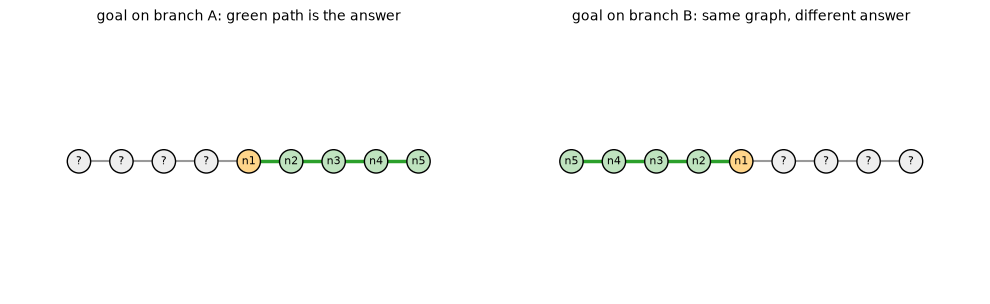

<sub>**Figure.** G(2,5): the two branches look identical until the goal is known. Notice that every token after the first choice is forced by the edge list, so the whole difficulty of the task is concentrated in one decision, the second path token.</sub>

In [5]:
sg = pk.StarGraph(d=2, l=5, n_nodes=50)
torch.manual_seed(3); ex = sg.batch(1, device="cpu")[0]
E = sg.E; edges = ex[:2 * E].reshape(E, 2).tolist(); start, goal = ex[2 * E + 1].item(), ex[2 * E + 2].item(); path = ex[sg.prefix:].tolist()
print(f"edges (shuffled): {edges}\nstart={start} goal={goal}\nanswer path: {path}\nfull sequence length T = {sg.T} (prompt {sg.prefix} + path {sg.l}), vocabulary {sg.vocab} (50 nodes + separator)")
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4)); viz.star_graph_figure(axs[0], 2, 5, pick=0, title="goal on branch A: green path is the answer"); viz.star_graph_figure(axs[1], 2, 5, pick=1, title="goal on branch B: same graph, different answer")
plt.tight_layout(); plt.show()
display(Markdown("<sub>**Figure.** G(2,5): the two branches look identical until the goal is known. Notice that every token after the first choice is forced by the edge list, so the whole difficulty of the task is concentrated in one decision, the second path token.</sub>"))
check("path tokens follow the edge list", all([path[i], path[i + 1]] in edges for i in range(sg.l - 1)))

**Why next-token prediction can fail here.** During training the model sees the *true* path prefix. Once it has seen $n_1,n_2$, every later token is a lookup in the edge list: "which edge starts at the node I just read?" This is easy and it drives the loss on those tokens to zero. The one token it cannot get by lookup is $n_2$, the choice of branch. The shortcut policy "follow edges forward, pick a branch at random at the centre" achieves almost zero training loss on all tokens *except* that one, and the gradient that remains on $n_2$ is a weak, noisy signal. Bachmann and Nagarajan call this a Clever Hans cheat. We write both policies in plain Python to measure what the shortcut is worth, and what a model that reasons from the goal backwards would get.

In [6]:
def solve_forward_shortcut(seq, rng):
    """What teacher-forced next-token training makes easy: follow edges forward; at the centre, pick a branch at random."""
    E = sg.E; ed = seq[:2 * E].reshape(E, 2).tolist(); start = seq[2 * E + 1].item(); out = [start]
    nxt = {}
    for u, v in ed: nxt.setdefault(u, []).append(v)
    while len(out) < sg.l:
        c = nxt[out[-1]]; out.append(c[rng.integers(len(c))] if len(c) > 1 else c[0])
    return out
def solve_backward(seq):
    """What a planner would do: walk from the goal back to the centre along reversed edges, then reverse."""
    E = sg.E; ed = seq[:2 * E].reshape(E, 2).tolist(); start, goal = seq[2 * E + 1].item(), seq[2 * E + 2].item()
    prev = {v: u for u, v in ed}; out = [goal]
    while out[-1] != start: out.append(prev[out[-1]])
    return out[::-1]
rng = np.random.default_rng(0); big = sg.batch(4000, device="cpu"); truth = big[:, sg.prefix:].tolist()
fw = np.mean([solve_forward_shortcut(s, rng) == t for s, t in zip(big, truth)]); bw = np.mean([solve_backward(s) == t for s, t in zip(big, truth)])
print(f"forward shortcut solves {fw*100:.1f}% of 4000 graphs   |   backward chaining from the goal solves {bw*100:.1f}%")
check("forward shortcut is at chance (1/d = 50%) within 3 points", abs(fw - 0.5) < 0.03); check("backward chaining solves every graph", bw == 1.0)
# where does the training loss on the shortcut live? ln(d) nats at exactly one path position, 0 elsewhere
per_pos = [0.0, math.log(2), 0.0, 0.0, 0.0]
print("loss a perfect forward-shortcut model keeps, per path token:", [round(v, 3) for v in per_pos], "-> average over the path", round(sum(per_pos) / 5, 3), "nats")

forward shortcut solves 50.0% of 4000 graphs   |   backward chaining from the goal solves 100.0%
loss a perfect forward-shortcut model keeps, per path token: [0.0, 0.693, 0.0, 0.0, 0.0] -> average over the path 0.139 nats


So a model that has learned only the shortcut is **exactly at chance, 50%**, while the training loss it still carries is just $\ln 2/5=0.139$ nats per path token, a number small enough to be mistaken for a nearly converged run. In our runs we found the first path token ($n_1$, a copy of the start node) and the lookups quickly reach near-zero loss; the interesting quantity is therefore *per-position* loss and the exact-path solve rate, not the average loss. To solve the task, the hidden state at the position before $n_2$ must already encode which branch leads to the goal, which is a statement about **what $h_t$ summarises**, not about how many tokens we predict. The next three sections are three different ways of asking $h_t$ to summarise more.

## 3. Multi-token prediction

**A tiny example.** Keep the same $h_t$ but ask it to predict *several* upcoming tokens. For the sequence $a\,b\,c\,d\,e\,f$ with $D=2$ extra heads, the hidden state at position $c$ is trained to predict $d$ (next), $e$ (+1) and $f$ (+2).

In [7]:
toks = list("abcdef"); D = 2
def multi_targets(seq, D, ignore=-100):
    """out[b,p,j] = seq[b, p+1+j] for j=0..D, or `ignore` past the end. j=0 is the ordinary next token."""
    B, T = seq.shape; out = torch.full((B, T - 1, D + 1), ignore, dtype=seq.dtype)
    for j in range(D + 1):
        n = T - 1 - j
        if n > 0: out[:, :n, j] = seq[:, 1 + j:]
    return out
s = torch.arange(6)[None]; tg = multi_targets(s, D)
print(f"{'position':>9} | next | +1   | +2"); 
for p in range(5): print(f"{toks[p]:>9} | " + " | ".join(f"{(toks[v] if v >= 0 else '-'):>4}" for v in tg[0, p].tolist()))
check("head j at position p targets token p+1+j", all(tg[0, p, j].item() == p + 1 + j for p in range(5) for j in range(D + 1) if p + 1 + j < 6))
check("targets past the end of the sequence are ignored", tg[0, 4, 1].item() == -100 and tg[0, 3, 2].item() == -100)

 position | next | +1   | +2
        a |    b |    c |    d
        b |    c |    d |    e
        c |    d |    e |    f
        d |    e |    f |    -
        e |    f |    - |    -


**General definition.** Gloeckle et al., 2024 train one shared transformer *trunk* $f_s$ and $n$ output heads $f_{h_1},\dots,f_{h_n}$, each a single transformer layer, with one shared unembedding matrix. Head $i$ reads the trunk output $z_t=f_s(x_{\le t})$ and predicts the token $i$ steps ahead:

$$\mathcal L_{\text{MTP}}=-\sum_{t}\sum_{i=1}^{n}\log p_\theta(x_{t+i}\mid z_t)\quad\text{with}\quad p_\theta(x_{t+i}\mid z_t)=\mathrm{softmax}\big(W_u\,f_{h_i}(z_t)\big).$$

Every head sees the same $z_t$ and none sees any other head's targets: **the heads predict marginals, independently**. At inference one can use only head 1 (ordinary decoding), or use the extra heads to draft tokens that head 1 then verifies, which is the self-speculative decoding that the paper reports gives up to 3x speed-up for 4-token prediction.

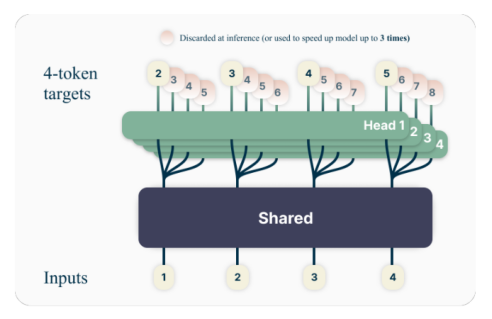

<sub>**Figure.** Reproduced from Figure 1 (top) of Gloeckle et al., 2024 ([arXiv:2404.19737](https://arxiv.org/abs/2404.19737)). A shared trunk feeds four output heads whose targets are the next four tokens; at inference the extra heads can be discarded or used for speed. Notice that the arrows from the trunk to the four heads all start from the same box: the heads cannot see each other's answers.</sub>

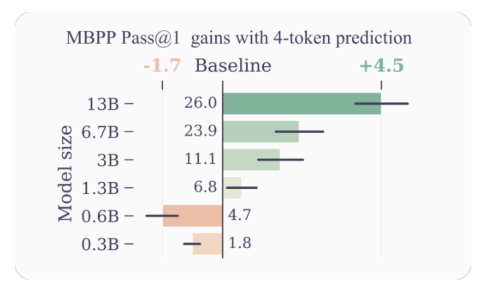

<sub>**Figure.** Reproduced from Figure 1 (bottom) of Gloeckle et al., 2024. MBPP pass@1 (a code-generation benchmark: the fraction of problems solved on the first attempt) with 4-token prediction versus the next-token baseline, by model size. Notice that the gain is negative for the 0.3B and 0.6B models (-0.1 and -1.7 points on the bar scale) and positive only from 1.3B upward: in the paper's data the benefit appears with scale.</sub>

In [8]:
show_paper_fig("fig_mtp_arch.png", "Reproduced from Figure 1 (top) of Gloeckle et al., 2024 ([arXiv:2404.19737](https://arxiv.org/abs/2404.19737)). A shared trunk feeds four output heads whose targets are the next four tokens; at inference the extra heads can be discarded or used for speed. Notice that the arrows from the trunk to the four heads all start from the same box: the heads cannot see each other's answers.", 5.2)
show_paper_fig("fig_mtp_mbpp.png", "Reproduced from Figure 1 (bottom) of Gloeckle et al., 2024. MBPP pass@1 (a code-generation benchmark: the fraction of problems solved on the first attempt) with 4-token prediction versus the next-token baseline, by model size. Notice that the gain is negative for the 0.3B and 0.6B models (-0.1 and -1.7 points on the bar scale) and positive only from 1.3B upward: in the paper's data the benefit appears with scale.", 5.2)

**How it is implemented.** We build the extra heads as one transformer block each on the trunk output and share the unembedding with the trunk. The loss adds, for each head, a cross-entropy against the shifted targets. We write it out and check that it matches the library implementation we use for the experiments.

In [9]:
def masked_ce(logits, targets, mask):
    ce = -F.log_softmax(logits, -1).gather(-1, targets[..., None])[..., 0]
    return (ce * mask).sum() / mask.sum().clamp_min(1)

def mtp_loss(trunk_h, shared_head, head_blocks, y, mask, D, lam=1.0):
    """trunk_h (B,T,dim). y (B,T) next-token targets. head_blocks[i-1] = transformer block of head i (predicts y shifted by i)."""
    B, T, _ = trunk_h.shape
    loss_ntp = masked_ce(shared_head(trunk_h), y, mask)                         # head 0: the ordinary next token, straight from the trunk
    aux = 0.0
    for i in range(1, D + 1):
        z_i = head_blocks[i - 1](trunk_h)                                        # head i: own transformer block on the SAME trunk output
        aux = aux + masked_ce(shared_head(z_i)[:, :T - i], y[:, i:], mask[:, i:]) / D
    return loss_ntp + lam * aux, loss_ntp, aux

sg = pk.StarGraph(2, 5, 50); seq = sg.batch(32); m, extra, _, kw = pk.build_method("MTP", sg)
x, y = seq[:, :-1], seq[:, 1:]; pm = pk.path_mask(sg, x.shape[1])[None].expand_as(y).float()
with torch.no_grad():
    h = m(x); mine = mtp_loss(h, m.head, kw["extra"].blocks, y, pm, kw["D"])[0]; lib = pk.loss_mtp(m, seq, sg, **kw)[0]
print("scratch MTP loss", mine.item(), "| predkit", lib.item())
check("scratch multi-token loss equals the loss used in the experiments", abs(mine.item() - lib.item()) < 1e-6)

scratch MTP loss 7.929930210113525 | predkit 7.929930210113525


**A cost, and the paper's way around it.** With a vocabulary of $V$ words the logits for $n$ heads have shape $(n,V)$ per position, and the vocabulary is usually far larger than the hidden size, so a naive implementation multiplies the largest tensor in training by $n$. Gloeckle et al. instead run the trunk forward once, then for each head in turn do its forward *and* backward, accumulate the gradient at the trunk output, and free that head's logits before starting the next. Peak memory for logits goes from $O(nV)$ to $O(V)$ at no extra compute, per the paper. We implement the trick and check it gives gradients identical to the naive version.

In [10]:
torch.manual_seed(0)
dim, V, n, B, T = 16, 200, 4, 3, 5
trunk = nn.Sequential(nn.Linear(8, dim), nn.Tanh()); heads = nn.ModuleList(nn.Linear(dim, dim) for _ in range(n)); unemb = nn.Linear(dim, V, bias=False)
inp = torch.randn(B, T, 8); tgt = torch.randint(0, V, (n, B, T))
def head_loss(i, z): return F.cross_entropy(unemb(torch.tanh(heads[i](z))).reshape(-1, V), tgt[i].reshape(-1))
# naive: build all n logits tensors, one backward
for p in list(trunk.parameters()) + list(heads.parameters()) + list(unemb.parameters()): p.grad = None
z = trunk(inp); total = sum(head_loss(i, z) for i in range(n)); total.backward()
g_naive = [p.grad.clone() for p in list(trunk.parameters()) + list(heads.parameters()) + list(unemb.parameters())]
# memory-efficient: detach the trunk output, run forward+backward per head, then one backward through the trunk
for p in list(trunk.parameters()) + list(heads.parameters()) + list(unemb.parameters()): p.grad = None
z = trunk(inp); zd = z.detach().requires_grad_(True)
for i in range(n): head_loss(i, zd).backward()                                   # logits of head i are freed after this call
z.backward(zd.grad)
g_eff = [p.grad.clone() for p in list(trunk.parameters()) + list(heads.parameters()) + list(unemb.parameters())]
err = max((a - b).abs().max().item() for a, b in zip(g_naive, g_eff)); print("max gradient difference naive vs memory-efficient:", err)
check("memory-efficient per-head backward gives identical gradients", err < 1e-6)
rows = [(nn_, nn_ * 4096 * 128000 / 1e9) for nn_ in (1, 2, 4, 8)]
print("logit elements per 4096-token sequence at V=128000 (fp32 GB, naive keeps all heads at once):", {k: round(v * 4, 1) for k, v in rows}, "-> memory-efficient keeps", round(1 * 4096 * 128000 * 4 / 1e9, 1), "GB for any n")

max gradient difference naive vs memory-efficient: 7.450580596923828e-09
logit elements per 4096-token sequence at V=128000 (fp32 GB, naive keeps all heads at once): {1: 2.1, 2: 4.2, 4: 8.4, 8: 16.8} -> memory-efficient keeps 2.1 GB for any n


Independent heads have a limitation that matters for our task, and Ahn et al. give a clean example. It comes next, because it motivates the third objective.

## 4. Joint multi-token prediction

**A tiny example.** Draw four fair coin flips $x_1,x_2,x_3,x_4$ and define $(x_5,x_6,x_7)=(x_1,x_2,x_3)$ if $x_4=1$ and the bitwise complement otherwise (Ahn et al., 2025, Section 2.2). At position 3 the model has seen $x_1,x_2,x_3$ but not $x_4$. Every *single* later token is a fair coin from its point of view, so a head predicting $x_5$ alone learns nothing from knowing $x_1$. Only the **joint** distribution of $(x_5,x_6,x_7)$ depends on $x_1x_2x_3$. We compute the exact entropies by enumerating all 16 outcomes.

In [11]:
def H(counts):
    p = np.array(list(counts.values()), float); p /= p.sum(); return float(-(p * np.log2(p)).sum())
def cond_entropy(rows, target, given):
    """H(target | given) in bits over equally likely rows (dicts)."""
    from collections import Counter, defaultdict
    groups = defaultdict(Counter)
    for r in rows: groups[tuple(r[g] for g in given)][tuple(r[t] for t in target)] += 1
    return sum(sum(c.values()) / len(rows) * H(c) for c in groups.values())
rows = []
for x1, x2, x3, x4 in itertools.product([0, 1], repeat=4):
    f = (lambda b: b) if x4 == 1 else (lambda b: 1 - b)
    rows.append(dict(x1=x1, x2=x2, x3=x3, x4=x4, x5=f(x1), x6=f(x2), x7=f(x3)))
# (i) a marginal head for x5 whose hidden state does / does not know x1..x3
no_info = cond_entropy(rows, ["x5"], []); with_info = cond_entropy(rows, ["x5"], ["x1", "x2", "x3"])
# (ii) the joint head for (x5,x6,x7) under the same two conditions
j_no = cond_entropy(rows, ["x5", "x6", "x7"], []); j_with = cond_entropy(rows, ["x5", "x6", "x7"], ["x1", "x2", "x3"])
# (iii) JTP's teacher-forced head: predicts x5 given h AND the forced x4
t_no = cond_entropy(rows, ["x5"], ["x4"]); t_with = cond_entropy(rows, ["x5"], ["x4", "x1", "x2", "x3"])
print(f"{'head':<46} | h ignores x1..x3 | h encodes x1..x3 | signal to encode")
for nm, a, b in [("independent head for x5 (marginal)", no_info, with_info), ("independent heads x5,x6,x7 (sum of marginals)", 3 * no_info, 3 * with_info),
                 ("joint head for (x5,x6,x7)", j_no, j_with), ("teacher-forced head for x5 given x4 (JTP)", t_no, t_with)]:
    print(f"{nm:<46} | {a:>12.2f} bit | {b:>12.2f} bit | {a - b:>5.2f} bit")
check("marginal heads get zero signal to encode x1..x3", abs(no_info - with_info) < 1e-9)
check("joint head loses 2 bits unless h encodes x1..x3", abs((j_no - j_with) - 2.0) < 1e-9)
check("teacher-forced head loses 1 bit unless h encodes x1", abs((t_no - t_with) - 1.0) < 1e-9)

head                                           | h ignores x1..x3 | h encodes x1..x3 | signal to encode
independent head for x5 (marginal)             |         1.00 bit |         1.00 bit |  0.00 bit
independent heads x5,x6,x7 (sum of marginals)  |         3.00 bit |         3.00 bit |  0.00 bit
joint head for (x5,x6,x7)                      |         3.00 bit |         1.00 bit |  2.00 bit
teacher-forced head for x5 given x4 (JTP)      |         1.00 bit |         0.00 bit |  1.00 bit


Independent heads are optimal at 1 bit per token *whether or not the hidden state stored $x_1x_2x_3$*, so their loss gives the trunk no reason to store it. A head that predicts $x_5$ **given the teacher-forced $x_4$** loses a full bit unless the hidden state carries $x_1$. That is the idea of JTP: let the future-token heads see earlier future tokens, so that they must extract the rest from $h_t$.

**General definition.** Ahn et al. decompose the joint over the next $D$ tokens with the chain rule and teacher-force the earlier ones:

$$\mathcal L_{\text{MTP}}=\frac1D\sum_{i=1}^{D}-\log \mathrm{head}\Big(\mathrm{Fetch}_{x_{t:t+i-1}}(h_{t-1})\Big)[x_{t+i}] .$$

Passing the forced tokens straight into the main transformer, as DeepSeek-AI's multi-token prediction does by running extra layers over the whole history, would let the model rely on them and on the history, bypassing $h_{t-1}$. JTP instead routes them through a small module, **Fetch**, that sees only the hidden state and the forced tokens. That narrow route is the *bottleneck*. The total loss is next-token loss plus $\lambda$ times this term.

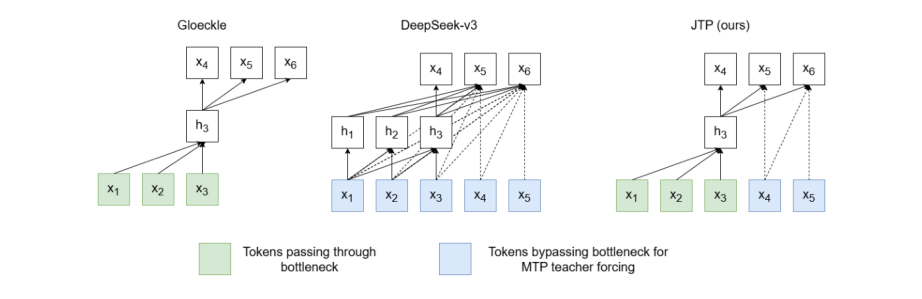

<sub>**Figure.** Reproduced from Figure 1 of Ahn et al., 2025 ([arXiv:2503.21801](https://arxiv.org/abs/2503.21801)) at position t=3. Left: independent heads (Gloeckle). Middle: DeepSeek-V3 style, where each future prediction reprocesses the whole history. Right: JTP, where x4 and x5 enter only through a small module next to h3. Notice that in the right panel the dotted teacher-forced arrows end at the bottleneck, not at the main trunk.</sub>

In [12]:
show_paper_fig("fig_jtp_vs_others.png", "Reproduced from Figure 1 of Ahn et al., 2025 ([arXiv:2503.21801](https://arxiv.org/abs/2503.21801)) at position t=3. Left: independent heads (Gloeckle). Middle: DeepSeek-V3 style, where each future prediction reprocesses the whole history. Right: JTP, where x4 and x5 enter only through a small module next to h3. Notice that in the right panel the dotted teacher-forced arrows end at the bottleneck, not at the main trunk.", 10)

**How it is implemented.** For every position $p$ (hidden state $h_p$ predicts $x_{p+1}$) we build a short sequence of $D+1$ vectors $u_j=\gamma h_p+\mathrm{Emb}(x_{p+j})$ for $j=0..D$. A single causal self-attention layer runs over $j$, and $\mathrm{Fetch}_j(h_p)=h_p+\mathrm{SelfAttn}(u_0..u_j)_j$ goes through the shared output head to predict $x_{p+1+j}$. The skip connection keeps $h_p$ the primary carrier of information. The paper's own next-token term passes through the attention layer as well (its Equation 5); we keep the ordinary head on $h_p$ for next-token prediction, a deliberate simplification that we note again in the results.

In [13]:
class Fetch(nn.Module):
    def __init__(self, dim, heads, gamma=1.0):
        super().__init__(); self.gamma = gamma; self.attn = nn.MultiheadAttention(dim, heads, batch_first=True); self.ln = nn.LayerNorm(dim)
    def forward(self, h, emb_win):                       # h (N,dim)   emb_win (N,D+1,dim)
        u = self.ln(self.gamma * h[:, None, :] + emb_win); J = u.shape[1]
        m = torch.triu(torch.ones(J, J, dtype=torch.bool), 1)
        return h[:, None, :] + self.attn(u, u, u, attn_mask=m, need_weights=False)[0]

def teacher_forced_windows(x, D):
    """win[b,p,j] = x[b,p+j] for j=0..D (zero-padded past the end; those targets are masked out of the loss)."""
    B, T = x.shape; pad = F.pad(x, (0, D)); return torch.stack([pad[:, j:j + T] for j in range(D + 1)], 2)

def jtp_loss(h, head, tok, fetch, x, y, mask, D, lam=1.0):
    B, T, dim = h.shape
    loss_ntp = masked_ce(head(h), y, mask)
    win = teacher_forced_windows(x, D)                                           # (B,T,D+1) forced input tokens
    out = fetch(h.reshape(B * T, dim), tok(win).reshape(B * T, D + 1, dim)).reshape(B, T, D + 1, dim)
    aux = sum(masked_ce(head(out[:, :T - j, j]), y[:, j:], mask[:, j:]) for j in range(1, D + 1)) / D
    return loss_ntp + lam * aux, loss_ntp, aux

xs = torch.arange(6)[None]; print("windows of forced tokens, D=2, for the sequence 0..5:"); print(teacher_forced_windows(xs, 2)[0])
m, extra, _, kw = pk.build_method("JTP", sg); x, y = seq[:, :-1], seq[:, 1:]
with torch.no_grad():
    h = m(x); mine = jtp_loss(h, m.head, m.tok, kw["fetch"], x, y, pm, kw["D"])[0]; lib = pk.loss_jtp(m, seq, sg, **kw)[0]
print("scratch JTP loss", mine.item(), "| predkit", lib.item()); check("scratch JTP loss equals the loss used in the experiments", abs(mine.item() - lib.item()) < 1e-6)

windows of forced tokens, D=2, for the sequence 0..5:
tensor([[0, 1, 2],
        [1, 2, 3],
        [2, 3, 4],
        [3, 4, 5],
        [4, 5, 0],
        [5, 0, 0]])
scratch JTP loss 7.928346633911133 | predkit 7.928346633911133


To see why this is a bottleneck rather than a second transformer, we test three properties. (a) $h_p$ cannot depend on future tokens, so the forced tokens reach the prediction *only* through Fetch. (b) Inside Fetch, the output for step $j$ must not depend on forced tokens after $j$ (otherwise it would be cheating on the chain rule). (c) Gradients from the future-token terms must reach $h_p$, since the whole point is to shape it.

In [14]:
torch.manual_seed(0); m, extra, _, kw = pk.build_method("JTP", sg); fe = kw["fetch"]; D = kw["D"]
xa = seq[:8, :-1].clone(); xb = xa.clone(); xb[:, 20:] = (xb[:, 20:] + 7) % 50                     # change tokens at positions >= 20
with torch.no_grad(): ha, hb = m(xa), m(xb)
check("(a) trunk hidden state at p=10 does not depend on tokens after p", torch.allclose(ha[:, 10], hb[:, 10], atol=1e-6))
hh = torch.randn(4, 128); ew = torch.randn(4, D + 1, 128); ew2 = ew.clone(); ew2[:, 3:] += 5.0               # perturb forced tokens j >= 3
with torch.no_grad(): oa, ob = fe(hh, ew), fe(hh, ew2)
check("(b) Fetch output at step j<=2 is unaffected by forced tokens at j>=3", torch.allclose(oa[:, :3], ob[:, :3], atol=1e-6) and not torch.allclose(oa[:, 3:], ob[:, 3:]))
h = m(xa); h.retain_grad(); loss = jtp_loss(h, m.head, m.tok, fe, xa, seq[:8, 1:], pm[:8], D)[2]; loss.backward()
check("(c) the future-token term sends gradient into the trunk hidden states", h.grad.abs().sum().item() > 0, f"|grad|={h.grad.abs().sum().item():.3g}")
n_fetch = sum(p.numel() for p in fe.parameters()); n_block = sum(p.numel() for p in pk.Block(128, 4).parameters())
print(f"Fetch parameters: {n_fetch:,} | one transformer block: {n_block:,} | ratio {n_fetch / n_block:.2f}")
check("Fetch is smaller than a full transformer block (attention only, no MLP)", n_fetch < n_block)

Fetch parameters: 66,304 | one transformer block: 198,272 | ratio 0.33


The three properties hold, and the module is about a third the size of a block in our configuration. The question that JTP leaves open, and that the next objective answers differently, is whether we need teacher-forced *tokens* at all: the hidden state could be asked to predict *itself* one step later.

## 5. Next-latent prediction

**A tiny example.** Give each position a two-number hidden state. Suppose at step $t$ the transformer produced $h_t=(1.0,\,0.0)$ and at step $t+1$ it produced $h_{t+1}=(1.0,\,2.0)$ after reading token $X_{t+1}$. A small dynamics model takes $(h_t,X_{t+1})$ and outputs a guess $\hat h_{t+1}$. The training signal is how far the guess is from the actual next hidden state, where the actual one is treated as a *constant* target (stop-gradient, so it is not pulled toward the guess).

In [15]:
h_t = torch.tensor([1.0, 0.0]); h_next = torch.tensor([1.0, 2.0]); tok_vec = torch.tensor([0.5, 0.5])              # embedding of X_{t+1}
W = torch.tensor([[0.0, 0.0, 1.0, 0.0], [0.0, 0.0, 0.0, 1.0]])                                                  # a toy dynamics map: h_hat = h + W [h, x]
h_hat = h_t + W @ torch.cat([h_t, tok_vec]); print("predicted next latent:", h_hat.tolist(), "| actual:", h_next.tolist())
def smooth_l1(a, b, beta=1.0):
    d = (a - b).abs(); return torch.where(d < beta, 0.5 * d ** 2 / beta, d - 0.5 * beta)
by_hand = smooth_l1(h_hat, h_next); print("element-wise smooth-L1:", by_hand.tolist(), "-> mean", by_hand.mean().item())
check("hand smooth-L1 matches F.smooth_l1_loss", abs(by_hand.mean().item() - F.smooth_l1_loss(h_hat, h_next).item()) < 1e-6)

predicted next latent: [1.5, 0.5] | actual: [1.0, 2.0]


element-wise smooth-L1: [0.125, 1.0] -> mean 0.5625


**General definition.** Teoh et al., 2025 add a *latent dynamics model* $p_\psi$ that predicts the next hidden state from the current hidden state and the next token, $\hat h_{t+1}=p_\psi(h_t,X_{t+1})$. They show (their Theorem 3.2) that if the model is trained so that (1) the output head predicts the next token correctly from $h_t$ and (2) the dynamics model predicts the transformer's own next hidden state, then $h_t$ must be a **belief state**: a compressed summary that is sufficient for predicting the future, because the two learned maps can be chained, $h_t\to X_{t+1}\to h_{t+1}\to X_{t+2}\dots$, to decode everything that follows. Three loss terms are used. Next-token cross-entropy is unchanged. The **latent loss** compares predicted and actual states over a horizon of $d$ recursive steps, with the actual state under stop-gradient $\mathrm{sg}[\cdot]$ to avoid collapse:

$$\mathcal L_{\text{next-}h}=\frac1d\sum_{i=1}^{d}\mathrm{SmoothL1}\big(\mathrm{sg}[h_{t+i}],\ \hat h_{t+i}\big),$$

and a **KL term** compares what a *frozen* copy of the output head predicts from the true and from the predicted state, $\frac1d\sum_i D_{\mathrm{KL}}\big(p(\cdot\mid \mathrm{sg}[h_{t+i}])\,\|\,p(\cdot\mid\hat h_{t+i})\big)$, so that the predicted latent also means the right thing in token space. At inference the dynamics model is not needed; it only shapes the representation during training. The architecture, parallel training and ordinary decoding are unchanged.

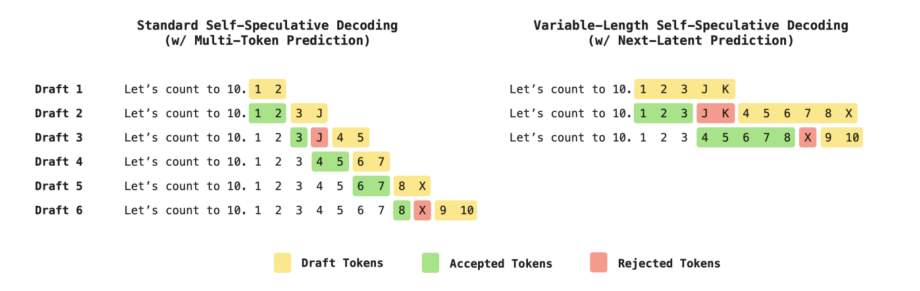

<sub>**Figure.** Reproduced from Figure 2 of Teoh et al., 2025 ([arXiv:2511.05963](https://arxiv.org/abs/2511.05963)). Left: self-speculative decoding with multi-token prediction drafts a fixed number of tokens per pass (here 2). Right: with NextLat the drafter can keep rolling the latent dynamics forward and draft a variable number of tokens. Green = accepted, red = rejected, yellow = draft. Notice that the right-hand panel needs 3 draft-verify cycles for the same text that takes the left 6.</sub>

In [16]:
show_paper_fig("fig_nextlat_specdec.png", "Reproduced from Figure 2 of Teoh et al., 2025 ([arXiv:2511.05963](https://arxiv.org/abs/2511.05963)). Left: self-speculative decoding with multi-token prediction drafts a fixed number of tokens per pass (here 2). Right: with NextLat the drafter can keep rolling the latent dynamics forward and draft a variable number of tokens. Green = accepted, red = rejected, yellow = draft. Notice that the right-hand panel needs 3 draft-verify cycles for the same text that takes the left 6.", 10)

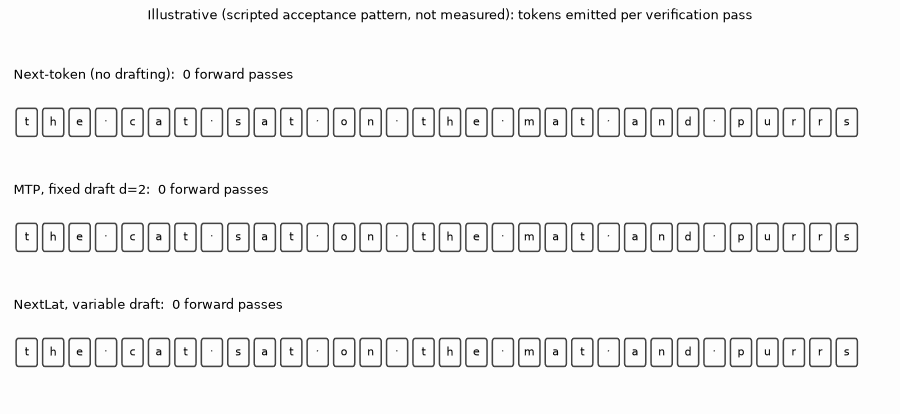

<sub>**Figure (animated, illustrative).** A scripted acceptance pattern, not a measurement: green = accepted tokens, red cross = rejected draft. It shows why a variable-length drafter can finish in fewer verification passes (Next-token (no drafting): 32, MTP, fixed draft d=2: 9, NextLat, variable draft: 4) than a fixed-length one, which is the mechanism, not a speed claim.</sub>

In [17]:
gif, passes = viz.specdec_gif("assets/gif_specdec.gif"); display(IPImage(filename=gif))
display(Markdown("<sub>**Figure (animated, illustrative).** A scripted acceptance pattern, not a measurement: green = accepted tokens, red cross = rejected draft. It shows why a variable-length drafter can finish in fewer verification passes (" + ", ".join(f"{k}: {v}" for k, v in passes.items()) + ") than a fixed-length one, which is the mechanism, not a speed claim.</sub>"))

**How it is implemented.** The loop below is a direct reading of the paper's Algorithm 1: shift hidden states back by one and tokens forward by one, predict the next hidden state, compute the two losses against *detached* targets, then feed the prediction back in for the next step of the horizon. The dynamics model here is a small MLP with a residual connection, the paper's own choice of "simple MLPs".

In [18]:
class Dynamics(nn.Module):
    def __init__(self, dim, tok_emb):
        super().__init__(); self.emb = tok_emb; self.net = nn.Sequential(nn.Linear(2 * dim, 2 * dim), nn.GELU(), nn.Linear(2 * dim, dim))
    def forward(self, h, tok): return h + self.net(torch.cat([h, self.emb(tok)], -1))          # (h_t, X_{t+1}) -> h_hat_{t+1}

def nextlat_loss(h, head, dyn, x, y, mask, horizon=1, lam_h=1.0, lam_kl=1.0):
    B, T, dim = h.shape
    logits = head(h); loss_ntp = masked_ce(logits, y, mask)
    frozen = nn.Linear(dim, head.out_features, bias=False).to(h.device); frozen.load_state_dict(head.state_dict()); frozen.requires_grad_(False)   # frozen copy of the output head
    cur, loss_h, loss_kl = h, 0.0, 0.0
    for i in range(1, horizon + 1):
        cur = cur[:, :-1]                                       # h_t for t = 0..T-1-i
        pred = dyn(cur, x[:, i:])                               # h_hat_{t+i}, with the teacher-forced token x_{t+i} as the "action"
        tgt = h[:, i:].detach()                                 # sg[h_{t+i}]
        m_i = mask[:, i:i + pred.shape[1]]                      # supervise where the token being predicted is part of the answer
        loss_h = loss_h + (F.smooth_l1_loss(pred, tgt, reduction="none").mean(-1) * m_i).sum() / m_i.sum().clamp_min(1)
        p_true = F.softmax(logits[:, i:].detach(), -1); logq = F.log_softmax(frozen(pred), -1)
        loss_kl = loss_kl + (((p_true * (p_true.clamp_min(1e-9).log() - logq)).sum(-1)) * m_i).sum() / m_i.sum().clamp_min(1)
        cur = pred                                              # recursive roll-out: the next step starts from the PREDICTED latent
    loss_h, loss_kl = loss_h / horizon, loss_kl / horizon
    return loss_ntp + lam_h * loss_h + lam_kl * loss_kl, loss_ntp, loss_h, loss_kl

torch.manual_seed(0); m, extra, _, kw = pk.build_method("NextLat", sg); dyn = kw["dyn"]; x, y = seq[:, :-1], seq[:, 1:]
with torch.no_grad():
    h = m(x); mine = nextlat_loss(h, m.head, dyn, x, y, pm, horizon=kw["horizon"])[0]; lib = pk.loss_nextlat(m, seq, sg, **kw)[0]
print("scratch NextLat loss", mine.item(), "| predkit", lib.item()); check("scratch NextLat loss equals the loss used in the experiments", abs(mine.item() - lib.item()) < 1e-5)

scratch NextLat loss 4.07786226272583 | predkit 4.07786226272583


Three properties are what make the objective what the paper says it is, and each can be tested directly. (a) *Stop-gradient*: the target hidden state must receive no gradient from the latent loss through the target path; the last position appears only as a target, so its gradient should be exactly zero. (b) *Frozen head*: the KL term must not change the output head's parameters. (c) *Recursion*: the two-step roll-out must equal applying the dynamics twice.

In [19]:
torch.manual_seed(0); m, extra, _, kw = pk.build_method("NextLat", sg); dyn = kw["dyn"]
h = m(x); h.retain_grad(); out = nextlat_loss(h, m.head, dyn, x, y, pm, horizon=1, lam_kl=0.0); out[2].backward()
check("(a) with stop-gradient the last position (target only) receives zero gradient from the latent loss", h.grad[:, -1].abs().max().item() == 0.0)
h2 = m(x); h2.retain_grad(); hh = h2[:, :-1]; pred = dyn(hh, x[:, 1:]); F.smooth_l1_loss(pred, h2[:, 1:]).backward()           # same loss WITHOUT detach
check("(a') without stop-gradient the same position would be pulled", h2.grad[:, -1].abs().max().item() > 0)
for p in list(m.parameters()) + list(dyn.parameters()): p.grad = None
nextlat_loss(m(x), m.head, dyn, x, y, pm, horizon=2)[0].backward(); g_full = m.head.weight.grad.clone()
for p in list(m.parameters()) + list(dyn.parameters()): p.grad = None
nextlat_loss(m(x), m.head, dyn, x, y, pm, horizon=2, lam_h=0.0, lam_kl=0.0)[0].backward(); g_ntp = m.head.weight.grad.clone()
d_head = (g_full - g_ntp).abs().max().item(); print("output-head gradient difference with vs without the KL/latent terms:", d_head)
check("(b) output head receives gradient only from the next-token loss", d_head < 1e-7)
with torch.no_grad():
    h = m(x); two = dyn(dyn(h[:, :-2], x[:, 1:-1]), x[:, 2:]); step = dyn(h[:, :-2], x[:, 1:-1]); step = dyn(step, x[:, 2:])
check("(c) two-step roll-out equals composing the dynamics twice", torch.allclose(two, step))
n_dyn = sum(p.numel() for p in dyn.parameters()); n_all = sum(p.numel() for p in m.parameters())
print(f"training-only parameters (dynamics MLP): {n_dyn:,}  = {n_dyn / n_all * 100:.1f}% of the {n_all:,}-parameter transformer; inference uses none of them")

output-head gradient difference with vs without the KL/latent terms: 0.0
training-only parameters (dynamics MLP): 105,216  = 17.2% of the 611,328-parameter transformer; inference uses none of them


All three behave as described. The practical consequence is variable-length drafting: because the dynamics model can be rolled forward indefinitely, one hidden state can generate a draft as long as we like, where $n$ independent heads can draft at most $n$ tokens. We implement that loop for NextLat, and the equivalent for the other three methods, in the experiment section. First, a picture of what each objective asks of one hidden state, as an animation.

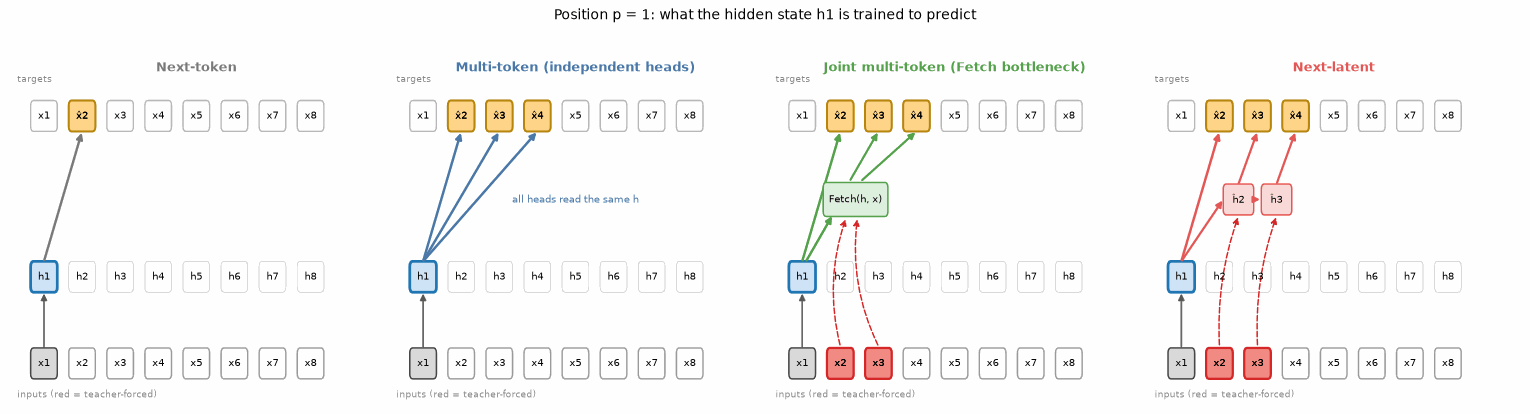

<sub>**Figure (animated).** For each position p the highlighted hidden state is trained on the orange targets. In the two right-hand panels the red inputs are teacher-forced future tokens: JTP sends them into the Fetch box beside h, NextLat sends them into the dynamics model that produces new latent states. Notice that only the independent-heads panel has every arrow leaving h directly.</sub>

In [20]:
gif = viz.supervision_gif("assets/gif_supervision.gif"); display(IPImage(filename=gif))
display(Markdown("<sub>**Figure (animated).** For each position p the highlighted hidden state is trained on the orange targets. In the two right-hand panels the red inputs are teacher-forced future tokens: JTP sends them into the Fetch box beside h, NextLat sends them into the dynamics model that produces new latent states. Notice that only the independent-heads panel has every arrow leaving h directly.</sub>"))

## 6. Comparing the four on the star graph

**Setup.** We reproduce the star-graph comparison of Ahn et al. at a much smaller scale: $G(2,5)$ with 50 node labels, prediction depth $D=l-2=3$, AdamW with learning rate $3\times10^{-4}$ and $(\beta_1,\beta_2)=(0.9,0.95)$, a fresh batch of graphs at every step. The paper uses a 6-layer, 384-dimensional transformer with batch 1024 and 10,000+ steps; we use 3 layers, 128 dimensions and batch 128 so that the whole comparison runs on a laptop CPU. Loss is applied to the path tokens only. We train each of the four methods once (one seed) with the same trunk architecture and the same data stream. Metric: **solve rate**, the fraction of 512 fresh graphs for which greedy decoding reproduces the entire path exactly (chance is 50%).

For NextLat we use horizon $d=3$ and loss weights $\lambda_{\text{next-}h}=\lambda_{\text{KL}}=1$; for MTP and JTP, $D=3$ and $\lambda=1$. We did not tune any of these.

In [21]:
CACHE = "assets/star_runs.pt"
METHODS = ["NTP", "MTP", "JTP", "NextLat"]
if os.path.exists(CACHE):
    runs = torch.load(CACHE, weights_only=False, map_location=DEVICE); print("loaded cached runs from", CACHE)
else:
    print("no cache: training all four methods (slow on CPU)"); runs = {k: pk.train_method(k) for k in METHODS}; torch.save(runs, CACHE)
STEPS = runs["NTP"]["hist"]["step"][-1]
print(f"{'method':<8} {'params':>10} {'overhead':>9}  sec/step | final solve rate | best solve rate")
for k in METHODS:
    r = runs[k]; print(f"{k:<8} {r['n_params']:>10,} {r['n_params']/runs['NTP']['n_params']*100-100:>8.1f}%  {r['sec_per_step']:>8.3f} | {r['hist']['solve'][-1]*100:>14.1f}% | {max(r['hist']['solve'])*100:>14.1f}%")
check("all four runs trained for the same number of steps", len({runs[k]['hist']['step'][-1] for k in METHODS}) == 1)

loaded cached runs from assets/star_runs.pt
method       params  overhead  sec/step | final solve rate | best solve rate
NTP         611,328      0.0%     0.145 |           46.3% |           52.3%
MTP       1,206,144     97.3%     0.204 |           39.1% |           43.9%
JTP         677,632     10.8%     0.188 |           55.3% |           55.3%
NextLat     710,016     16.1%     0.182 |           80.9% |           80.9%


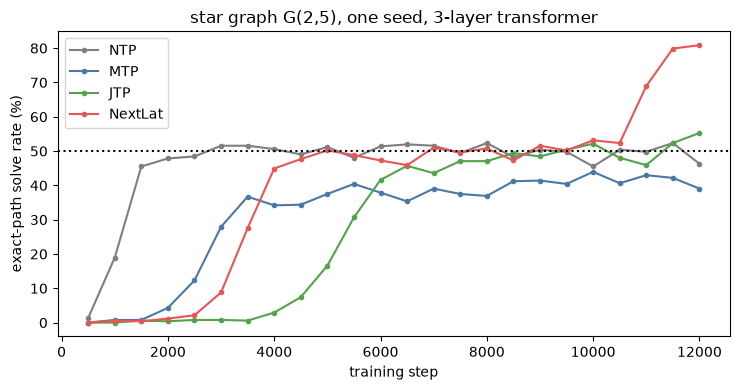

<sub>**Figure.** Measured solve rate during training. The dotted line is the 50% that the forward-shortcut policy of section 2 achieves. Notice which curves leave the dotted line and when; with one seed, differences of a few points are within what we would expect from run-to-run variation.</sub>

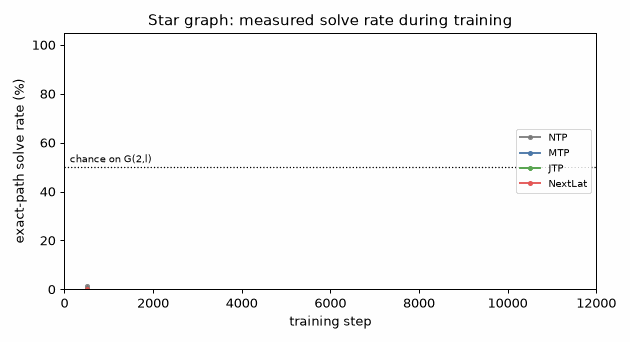

<sub>**Figure (animated).** The same measured curves, revealed one evaluation at a time.</sub>

In [22]:
fig, ax = plt.subplots(figsize=(7.5, 4)); cols = dict(NTP=viz.C["ntp"], MTP=viz.C["mtp"], JTP=viz.C["jtp"], NextLat=viz.C["nl"])
for k in METHODS: ax.plot(runs[k]["hist"]["step"], np.array(runs[k]["hist"]["solve"]) * 100, "-o", ms=3, color=cols[k], label=k)
ax.axhline(50, color="k", ls=":"); ax.set_xlabel("training step"); ax.set_ylabel("exact-path solve rate (%)"); ax.legend(); ax.set_title("star graph G(2,5), one seed, 3-layer transformer"); plt.tight_layout(); plt.show()
display(Markdown("<sub>**Figure.** Measured solve rate during training. The dotted line is the 50% that the forward-shortcut policy of section 2 achieves. Notice which curves leave the dotted line and when; with one seed, differences of a few points are within what we would expect from run-to-run variation.</sub>"))
hist = {k: (runs[k]["hist"]["step"], runs[k]["hist"]["solve"]) for k in METHODS}
display(IPImage(filename=viz.training_gif(hist, "assets/gif_training.gif"))); display(Markdown("<sub>**Figure (animated).** The same measured curves, revealed one evaluation at a time.</sub>"))

**Per-position diagnosis.** The solve rate says whether the final answer is right; the per-position loss says *where* a model is stuck. For each trained model we measure the teacher-forced cross-entropy on each of the five path tokens over 2048 fresh graphs. In section 2 we computed that a forward-shortcut model should sit at $\ln 2=0.693$ nats on token 2 and near zero elsewhere.

method   | token 1 | token 2 | token 3 | token 4 | token 5
NTP      |   0.000 |   0.761 |   0.001 |   0.001 |   0.000
MTP      |   0.014 |   0.934 |   0.110 |   0.137 |   0.000
JTP      |   0.009 |   0.805 |   0.006 |   0.019 |   0.000
NextLat  |   0.008 |   0.424 |   0.001 |   0.001 |   0.000


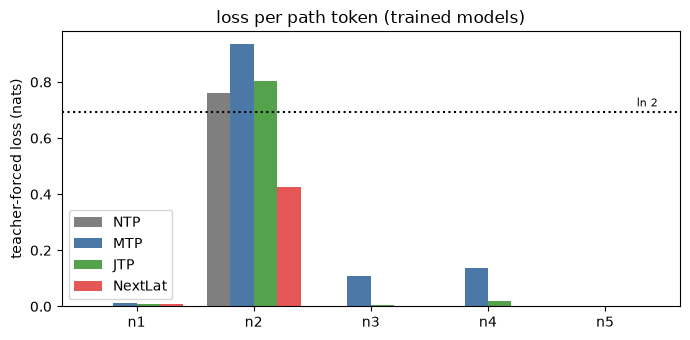

<sub>**Figure.** Teacher-forced loss at each path token. The dotted line is ln 2, the value a forward-shortcut model keeps on the branch choice (token n2). Notice whether any method brings n2 well below it: that is the signature of a hidden state that has learned the goal-conditioned branch.</sub>

In [23]:
def rebuild(k):
    sg_ = pk.StarGraph(2, 5, 50); m, ex, fn, kw = pk.build_method(k, sg_); m.load_state_dict(runs[k]["model"])
    for name, sd in runs[k]["extra"].items(): ex[name].load_state_dict(sd)
    return sg_, m, ex, kw
@torch.no_grad()
def per_position_loss(k, n=2048):
    sg_, m, ex, kw = rebuild(k); m.eval(); s = sg_.batch(n); h = m(s[:, :-1]); lg = m.head(h)
    ce = F.cross_entropy(lg.reshape(-1, lg.shape[-1]), s[:, 1:].reshape(-1), reduction="none").view(n, -1)
    return ce[:, sg_.prefix - 1:].mean(0).tolist()                      # the l path tokens
ppl = {k: per_position_loss(k) for k in METHODS}
print(f"{'method':<8}" + "".join(f" | token {j + 1}" for j in range(5)))
for k in METHODS: print(f"{k:<8}" + "".join(f" | {v:>7.3f}" for v in ppl[k]))
fig, ax = plt.subplots(figsize=(7, 3.5)); w = .2
for i, k in enumerate(METHODS): ax.bar(np.arange(5) + (i - 1.5) * w, ppl[k], w, color=cols[k], label=k)
ax.axhline(math.log(2), color="k", ls=":"); ax.text(4.45, math.log(2) + .02, "ln 2", ha="right", fontsize=8); ax.set_xticks(range(5)); ax.set_xticklabels([f"n{j + 1}" for j in range(5)]); ax.set_ylabel("teacher-forced loss (nats)"); ax.legend(); ax.set_title("loss per path token (trained models)")
plt.tight_layout(); plt.show()
display(Markdown("<sub>**Figure.** Teacher-forced loss at each path token. The dotted line is ln 2, the value a forward-shortcut model keeps on the branch choice (token n2). Notice whether any method brings n2 well below it: that is the signature of a hidden state that has learned the goal-conditioned branch.</sub>"))

**Drafting from one hidden state.** The practical test of "does $h_t$ contain a plan" is to take the hidden state at the last prompt position and decode the whole path from it *without running the transformer again*. We implement that for each method: MTP reads its extra heads in parallel; JTP rolls Fetch forward with its own drafted tokens as the forced inputs; NextLat alternates the output head and the dynamics model; NTP has no mechanism beyond the first token, so it is scored by its ordinary autoregressive decoding (the solve rate). We score the first $D+1=4$ path tokens.

In [24]:
@torch.no_grad()
def draft_from_prompt(k, n=1024):
    """Draft path tokens 1..D+1 from the hidden state at the last prompt token. Returns per-offset exact-prefix accuracy."""
    sg_, m, ex, kw = rebuild(k); m.eval(); s = sg_.batch(n); P = sg_.prefix; D = sg_.l - 2; K = D + 1
    h = m(s[:, :P])[:, -1]                                               # (n,dim) hidden state at the final prompt token
    drafts = [m.head(h).argmax(-1)]
    if k == "MTP":
        hseq = m(s[:, :P])
        for i in range(1, D + 1): drafts.append(m.head(ex["extra"].blocks[i - 1](hseq))[:, -1].argmax(-1))
    elif k == "JTP":
        forced = [s[:, P - 1]]                                           # x_p (the last prompt token), then the drafted tokens
        for j in range(1, D + 1):
            forced.append(drafts[-1])
            ew = m.tok(torch.stack(forced, 1))                           # (n,j+1,dim)
            drafts.append(m.head(ex["fetch"](h, ew)[:, -1]).argmax(-1))
    elif k == "NextLat":
        cur = h
        for i in range(1, D + 1):
            cur = ex["dyn"](cur, drafts[-1]); drafts.append(m.head(cur).argmax(-1))
    elif k == "NTP":
        return None
    truth = s[:, P:P + K]; D_ = torch.stack(drafts, 1)
    return [(D_[:, :j + 1] == truth[:, :j + 1]).all(1).float().mean().item() for j in range(K)]
la = {k: draft_from_prompt(k) for k in ["MTP", "JTP", "NextLat"]}
print(f"{'method':<8}" + "".join(f" | first {j + 1} tok" for j in range(4)))
for k, v in la.items(): print(f"{k:<8}" + "".join(f" | {x*100:>8.1f}%" for x in v))

method   | first 1 tok | first 2 tok | first 3 tok | first 4 tok
MTP      |    100.0% |     46.7% |     22.9% |      9.8%
JTP      |    100.0% |     16.0% |      2.7% |      0.6%
NextLat  |    100.0% |     76.1% |     76.1% |     76.1%


(The comparison above is an exact-prefix score: a draft of length $j$ counts only if all $j$ tokens are right. Token 1 is a copy of the start node and is trivial; token 2 is the branch choice.)

## 7. What did not work and what each costs

We report what happened, including the parts that do not match the papers' claims. All numbers are from the single-seed, 12,000-step runs above (3-layer, 128-dimensional transformer, $G(2,5)$, chance 50%).

**Next-token prediction stayed at the shortcut.** Solve rate 46.3% (best 52.3% over training), and the loss on the branch-choice token is 0.761 nats against the $\ln 2=0.693$ that the forward-shortcut policy keeps (section 2). The other four path tokens are at or below 0.001 nats. We found that a loss curve alone would have hidden this: the average path loss was 0.15 nats at the end, small enough to look converged.

**Independent multi-token heads did not help in our setting.** MTP finished at 39.1% (best 43.9%), below chance, with 97.3% more parameters than the baseline (each of its three extra heads is a full transformer block) and 1.4x the step time. Its losses on tokens 3 and 4 (0.110 and 0.137 nats) are the highest of the four methods, and drafting from one hidden state gets 46.7% of the first two tokens and 9.8% of four. Ahn et al. report that Gloeckle et al.'s method solves $G(2,5)$ but not larger graphs at their scale; we did not reproduce that result, and we cannot say whether the gap comes from our smaller model, our single seed, or our head design.

**JTP learned late and only just cleared chance.** Its next-token loss lagged the baseline for the first 4,000 steps (solve rate 2.9% at step 4,000 versus 50.6% for the baseline) and it reached 55.3% at step 12,000, with the auxiliary loss still falling (1.36 at the end). Ahn et al. report near-100% on $G(2,5)$ with a 6-layer, 384-dimensional model and a batch of 1024; we did not reproduce that and ran at roughly 1/8 of their batch and 1/3 of their width. Drafting from the prompt hidden state with its own drafted tokens as the forced inputs is poor (16.0% for two tokens); we do not know whether that is a property of JTP or of our draft procedure, because JTP is trained with the *true* future tokens forced, not drafted ones. We also simplified its next-token term (section 4).

**NextLat was the only method clearly above chance, with caveats.** 80.9% at step 12,000, branch-choice loss 0.424 nats (below $\ln 2$, so the hidden state is using the goal), and from one hidden state the dynamics model drafts all four tokens correctly in 76.1% of graphs, which equals its accuracy on the branch choice because every later token is forced. The caveats are real: it is one seed; the solve rate jumped from 53.1% at step 10,000 to 80.9% at 12,000, so the curve is not converged and we would expect further movement; and the latent-loss weight, the KL weight and the horizon were not tuned. Its cost is the training-only dynamics MLP: 105,216 parameters, 17.2% of the transformer (16.1% of the total), and 1.26x the step time of the baseline in our (CPU, contended) setting. Inference uses none of it.

**Slower start.** All three multi-token variants were slower than next-token prediction to learn the easy lookups: at step 4,000 the solve rates were 50.6% (NTP), 44.9% (NextLat), 34.2% (MTP) and 2.9% (JTP). In our setting the extra objectives pay a cost early in training and the question is whether they pay it back, which only NextLat did within our budget.

| objective | what $h_t$ must predict | extra parameters | what it costs | our result (G(2,5), 12k steps) |
|---|---|---|---|---|
| next-token | next token only | none | nothing | 46.3% |
| multi-token (independent) | next $D+1$ tokens as marginals | one block per head (+97.3% here) | memory for $n$ sets of logits unless the per-head backward trick is used | 39.1% |
| joint multi-token | future tokens given forced earlier ones, via Fetch | attention layer (+10.8% here) | extra attention over $D+1$ vectors per position | 55.3% |
| next-latent | its own next hidden state, plus KL in token space | MLP, training only (+16.1% here) | extra forward over the dynamics model per horizon step | 80.9% |

In [25]:
rows = []
for k in METHODS:
    r = runs[k]; rows.append((k, r['n_params'], r['sec_per_step'], r['hist']['solve'][-1], max(r['hist']['solve'])))
base = rows[0]
display(Markdown("| method | trainable params | extra params vs NTP | sec/step (CPU, contended) | step-time vs NTP | final solve | best solve |\n|---|---|---|---|---|---|---|\n" +
    "\n".join(f"| {k} | {p:,} | {(p/base[1]-1)*100:+.1f}% | {s:.3f} | {s/base[2]:.2f}x | {f*100:.1f}% | {b*100:.1f}% |" for k, p, s, f, b in rows)))

| method | trainable params | extra params vs NTP | sec/step (CPU, contended) | step-time vs NTP | final solve | best solve |
|---|---|---|---|---|---|---|
| NTP | 611,328 | +0.0% | 0.145 | 1.00x | 46.3% | 52.3% |
| MTP | 1,206,144 | +97.3% | 0.204 | 1.41x | 39.1% | 43.9% |
| JTP | 677,632 | +10.8% | 0.188 | 1.30x | 55.3% | 55.3% |
| NextLat | 710,016 | +16.1% | 0.182 | 1.26x | 80.9% | 80.9% |

## 8. Closing thoughts

Next-token prediction is the baseline that made large language models practical; multi-token prediction (Gloeckle et al., 2024) showed that asking the hidden state to anticipate more than one token can help downstream accuracy and enable faster decoding; JTP (Ahn et al., 2025) and NextLat (Teoh et al., 2025) argue that *how* the future is supervised matters, through a representation bottleneck and through latent dynamics respectively. The idea of treating hidden states as belief states has a longer lineage in predictive state representations and in self-predictive reinforcement learning, which the NextLat paper cites. We credit the authors of all three papers for the figures reproduced above and for the algorithms we reimplemented from their descriptions; any error in our reimplementation is ours.

**What is open.** Our runs are single-seed and small, on one synthetic task; we have not tested any of the four on language modelling, so none of the language-model numbers in this notebook (12%, 17%, 3x, 3.3x) are ours. We simplified JTP's next-token term (an ordinary head on $h_p$ rather than the paper's Equation 5), we did not tune loss weights or horizons, and we did not implement the DeepSeek-V3 style sequential multi-token module, the paper's other baseline. Ahn et al. describe their language-modelling result as preliminary and report a small increase in next-token loss (3.062 to 3.100 in their sanity check), and the NextLat paper notes belief-state guarantees hold for an idealised optimiser, which our small runs do not test.

Checks run in this notebook:

In [26]:
report()

PASS hand-computed next-token loss equals F.cross_entropy
PASS scratch next-token loss equals F.cross_entropy on a real forward pass
PASS changing a later token leaves earlier hidden states unchanged (causality)
PASS path tokens follow the edge list
PASS forward shortcut is at chance (1/d = 50%) within 3 points
PASS backward chaining solves every graph
PASS head j at position p targets token p+1+j
PASS targets past the end of the sequence are ignored
PASS scratch multi-token loss equals the loss used in the experiments
PASS memory-efficient per-head backward gives identical gradients
PASS marginal heads get zero signal to encode x1..x3
PASS joint head loses 2 bits unless h encodes x1..x3
PASS teacher-forced head loses 1 bit unless h encodes x1
PASS scratch JTP loss equals the loss used in the experiments
PASS (a) trunk hidden state at p=10 does not depend on tokens after p
PASS (b) Fetch output at step j<=2 is unaffected by forced tokens at j>=3
PASS (c) the future-token term sends gra